# Hipótesis multivariada (grupo)

A igual ocupación y tipo de habitación, el ingreso anual estimado está influenciado por el barrio.

Variables: `room_type`, `estimated_occupancy_l365d`, `estimated_revenue_l365d` y `neighbourhood_cleansed`. 

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

listings = pd.read_csv("listings (1).csv.gz")
calendar_dataset = pd.read_csv("calendar.csv.gz")

listings['instant_bookable'].value_counts(dropna=False)

#copiamos el conjunto para preservarlo
preprocessed_dataset = listings.copy()

#borramos columnas con todos sus valores nulos
preprocessed_dataset = preprocessed_dataset.drop('neighborhood_overview', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_since', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_response_time', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_response_rate', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_acceptance_rate', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_thumbnail_url', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_neighbourhood', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_total_listings_count', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_verifications', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('neighbourhood', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('neighbourhood_group_cleansed', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('calendar_updated', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('instant_bookable', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('listing_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_profile_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_profile_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_name',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('scrape_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('picture_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('license',axis=1)

**Preprocesamiento de las variables del análisis**

_Selección de variables_: se trabajó solo con room_type, estimated_occupancy_l365d, estimated_revenue_l365d y neighbourhood_cleansed, que son las que intervienen en la hipótesis, sin preprocesar el resto del dataset.

_Nulos_: se eliminaron las 1.797 filas con estimated_revenue_l365d nulo, ya que es la variable respuesta y no se puede analizar sin ella (quedaron 27.888 filas).

_Ceros_: se eliminaron las 6.346 filas con `estimated_revenue_l365d` igual a 0 (todas tenían también ocupación 0). Son alojamientos sin noches ocupadas estimadas en el último año, por lo que no aportan información para comparar ingresos entre barrios. Además, concentran una masa de valores en 0 que distorsiona la distribución y la varianza (quedaron 21.542 filas).

In [16]:
cols = ["room_type", "estimated_occupancy_l365d",
        "estimated_revenue_l365d", "neighbourhood_cleansed"]
df_multi = listings[cols].dropna().copy()
print(df_multi.shape)  # (27888, 4)

(27888, 4)


In [18]:
df_multi = df_multi[df_multi["estimated_revenue_l365d"] > 0].copy()
print(df_multi.shape)  # (21542, 4)

(21542, 4)


_Outliers_: se eliminaron los valores de ingreso por encima de Q3 + 1,5·IQR (≈ 36,7 M), lo que representa 1.008 filas (≈ 4,7 %). No hay outliers por debajo, porque la cerca inferior es negativa. Los valores extremos influyen mucho en las medias y las varianzas, y dominan la comparación entre grupos. Además, casi todos los outliers corresponden a departamentos enteros (1.006 de 1.008), por lo que no se pierde información de las categorías con poca muestra: las habitaciones de hotel (21) y compartidas (83) mantienen todas sus filas con y sin outliers.

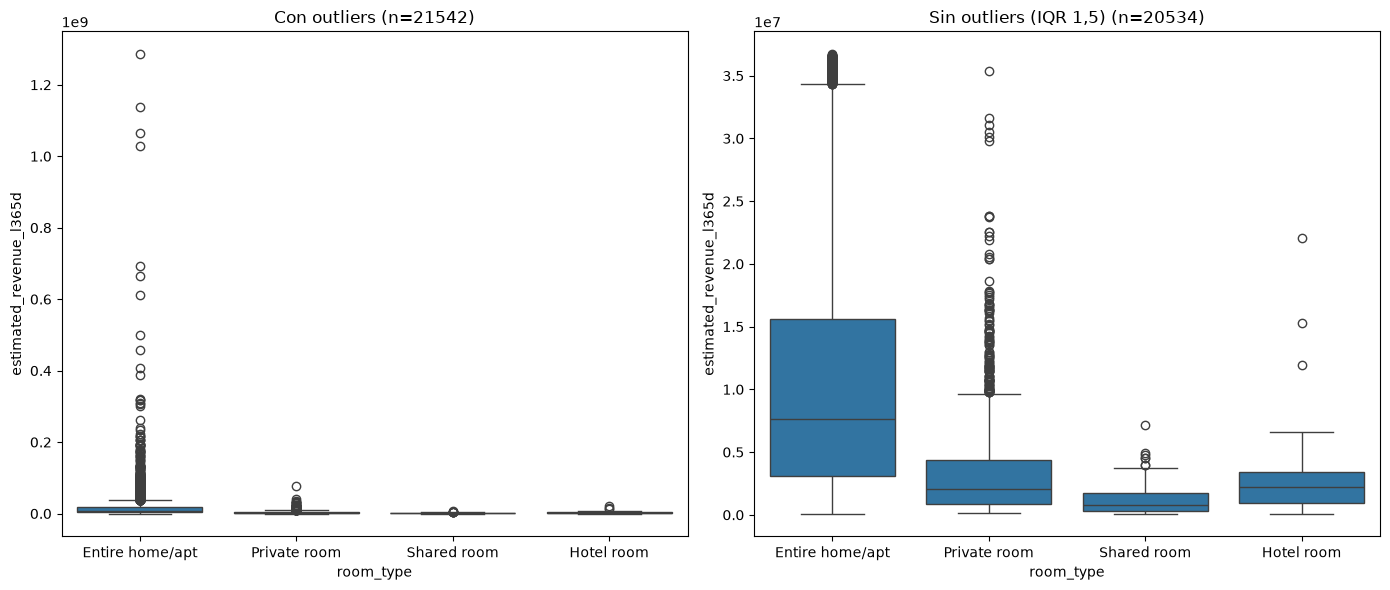

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

q1, q3 = df_multi["estimated_revenue_l365d"].quantile([0.25, 0.75])
limite_sup = q3 + 1.5 * (q3 - q1)
df_sin_out = df_multi[df_multi["estimated_revenue_l365d"] <= limite_sup]

orden = ["Entire home/apt", "Private room", "Shared room", "Hotel room"]
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, data, t in [(ax[0], df_multi, "Con outliers"),
                   (ax[1], df_sin_out, "Sin outliers (IQR 1,5)")]:
    sns.boxplot(data=data, x="room_type", y="estimated_revenue_l365d",
                order=orden, ax=a)
    a.set_title(f"{t} (n={len(data)})")
plt.tight_layout()
plt.show()

In [25]:
q1, q3 = df_multi["estimated_revenue_l365d"].quantile([0.25, 0.75])
iqr = q3 - q1
limite_sup = q3 + 1.5 * iqr

df_multi = df_multi[df_multi["estimated_revenue_l365d"] <= limite_sup].copy()
print(df_multi.shape)  # (20534, 4)

(20534, 4)


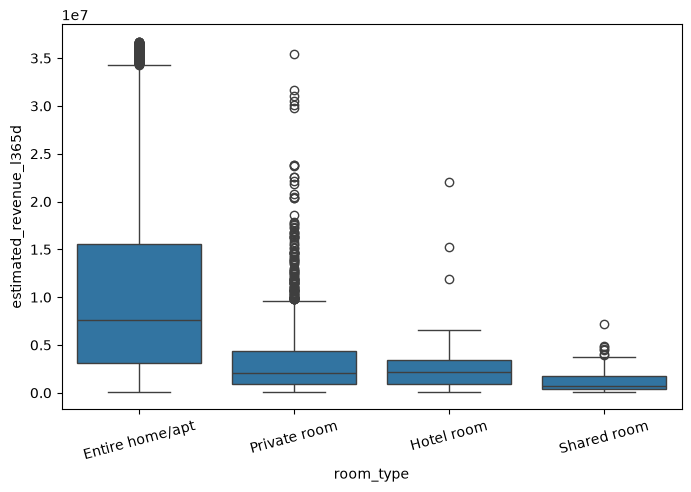

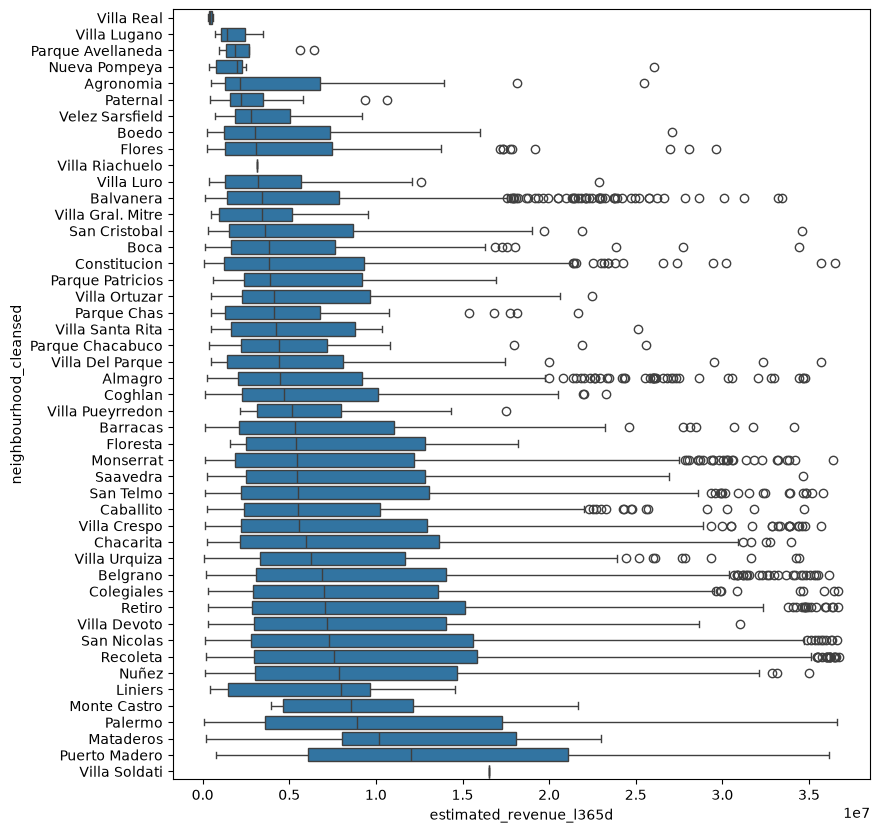

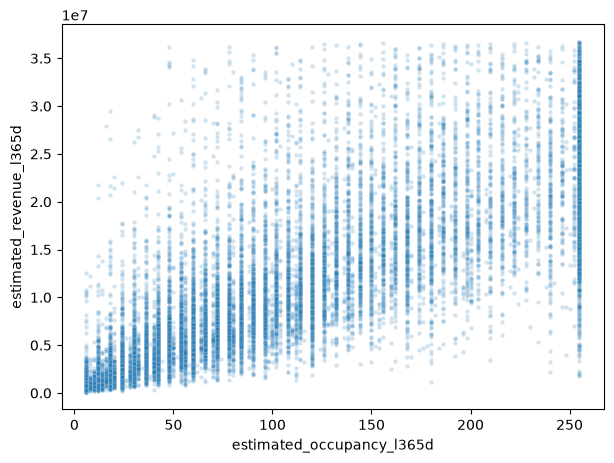

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. log(ingreso) por tipo de habitación
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_multi, x='room_type', y='estimated_revenue_l365d')
plt.xticks(rotation=15)
plt.show()

# 2. log(ingreso) por barrio, ordenado por mediana
orden = df_multi.groupby('neighbourhood_cleansed')['estimated_revenue_l365d'].median().sort_values().index
plt.figure(figsize=(9, 10))
sns.boxplot(data=df_multi, y='neighbourhood_cleansed', x='estimated_revenue_l365d', order=orden)
plt.show()

# 3. log(ingreso) contra log(ocupación)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_multi, x='estimated_occupancy_l365d', y='estimated_revenue_l365d', alpha=0.2, s=10)
plt.show()

En el boxplot de ingreso por barrio, los barrios con muy pocas observaciones muestran cajas degeneradas: Villa Real, Villa Riachuelo y Villa Soldati aparecen como un punto o una línea (entre 1 y 2 alojamientos), y Villa Lugano, Nueva Pompeya o Parque Avellaneda tienen cajas muy angostas (entre 3 y 9). Con tan pocos datos, la mediana y los cuartiles dependen de uno o dos alojamientos y no representan al barrio. La tabla cruzada barrio x tipo de habitación confirma que esos barrios tienen casi todas las celdas vacías o con muy pocos casos.

Se adopta 30 observaciones como mínimo por barrio, una regla práctica habitual para que el promedio de un grupo sea mínimamente estable y comparable. Por debajo, las diferencias entre barrios podrían deberse al azar de la muestra y no a un efecto real. Se descartó agrupar estos barrios en una categoría "Otros" porque mezclaría barrios muy distintos y no tendría una interpretación geográfica. La pérdida es de 203 filas (≈ 1 %): quedan 30 barrios y 20.331 filas.

In [27]:
tabla = pd.crosstab(df_multi['neighbourhood_cleansed'], df_multi['room_type'])
tabla['Total'] = tabla.sum(axis=1)
tabla = tabla.sort_values('Total', ascending=False)
tabla.loc['Total'] = tabla.sum()

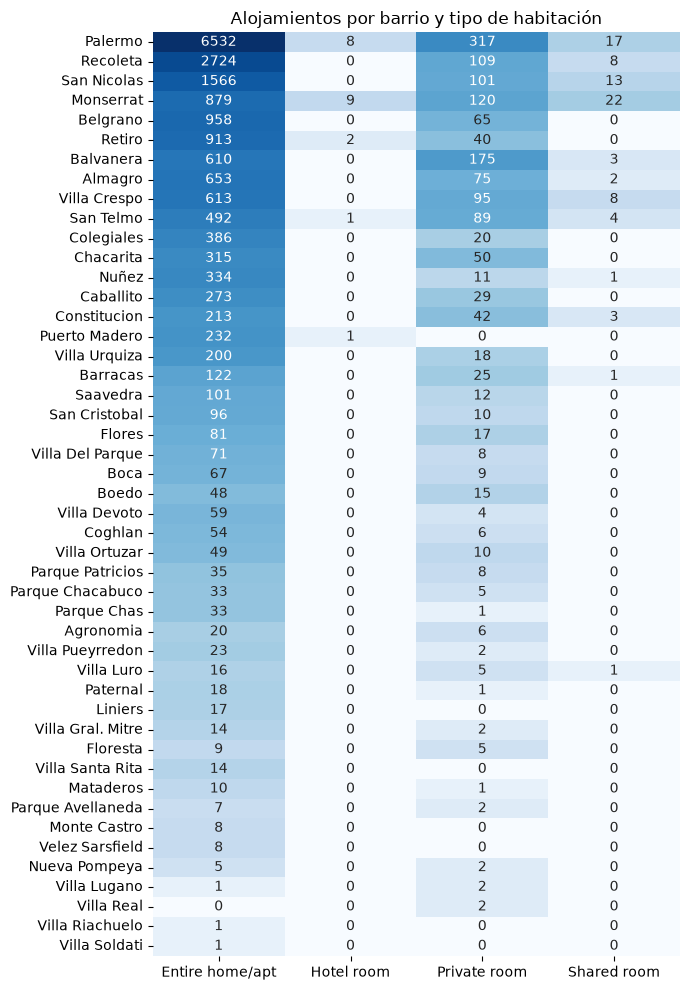

In [29]:
import numpy as np

datos = tabla.drop(index='Total', columns='Total')

plt.figure(figsize=(7, 10))
sns.heatmap(np.log1p(datos), annot=datos, fmt='d', cmap='Blues', cbar=False)
plt.title('Alojamientos por barrio y tipo de habitación')
plt.xlabel('')
plt.ylabel('')
plt.tight_layout()
plt.savefig('tabla_cruzada.png', dpi=200)
plt.show()

In [30]:
conteo = df_multi["neighbourhood_cleansed"].value_counts()
barrios_validos = conteo[conteo >= 30].index
df_multi = df_multi[df_multi["neighbourhood_cleansed"].isin(barrios_validos)].copy()
print(df_multi.shape, df_multi["neighbourhood_cleansed"].nunique())  # (20331, 4) 30

(20331, 4) 30


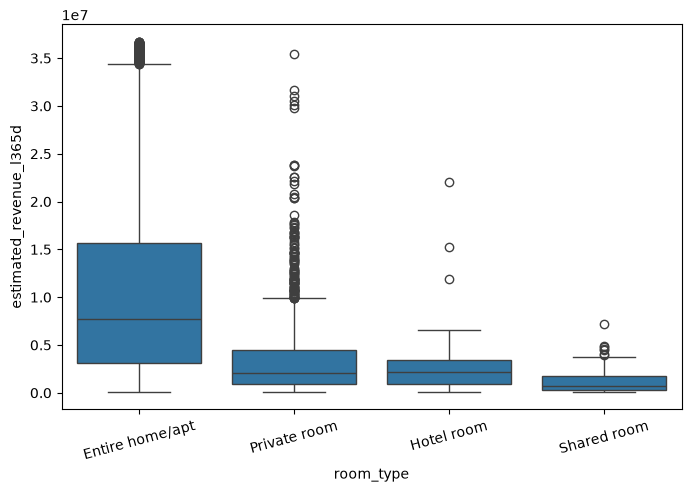

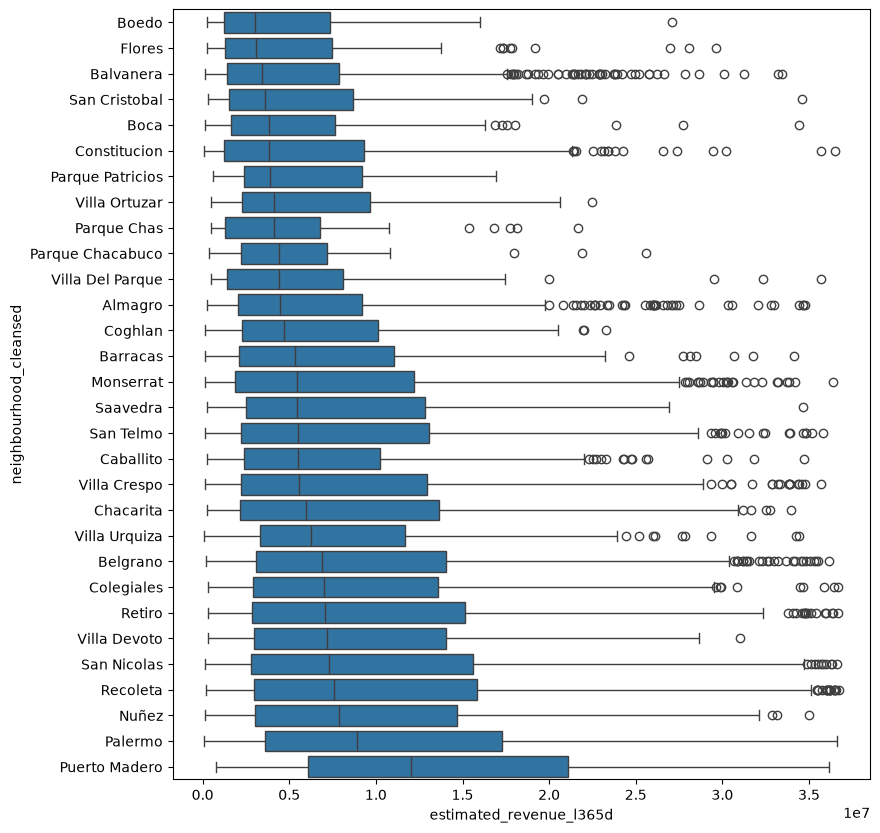

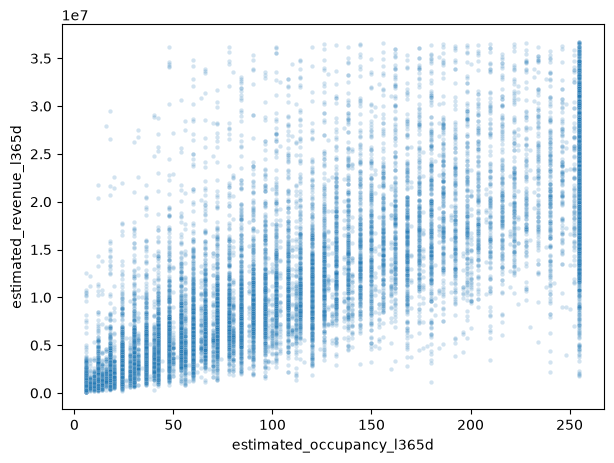

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. log(ingreso) por tipo de habitación
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_multi, x='room_type', y='estimated_revenue_l365d')
plt.xticks(rotation=15)
plt.show()

# 2. log(ingreso) por barrio, ordenado por mediana
orden = df_multi.groupby('neighbourhood_cleansed')['estimated_revenue_l365d'].median().sort_values().index
plt.figure(figsize=(9, 10))
sns.boxplot(data=df_multi, y='neighbourhood_cleansed', x='estimated_revenue_l365d', order=orden)
plt.show()

# 3. log(ingreso) contra log(ocupación)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_multi, x='estimated_occupancy_l365d', y='estimated_revenue_l365d', alpha=0.2, s=10)
plt.show()

**Observaciones del análisis exploratorio**

- _Ingreso por barrio_: las medianas y la dispersión del ingreso cambian de un barrio a otro, lo que sugiere que el barrio influye en el ingreso de un host.
- _Ingreso por tipo de habitación_: las cajas se ordenan de forma coherente con lo que ofrece cada categoría: los departamentos enteros tienen los mayores ingresos y las habitaciones compartidas los menores.
- _Ingreso vs ocupación_: la nube sube de forma aproximadamente lineal con la ocupación, por lo que es necesario controlar por esta variable. Además, la dispersión del ingreso crece al aumentar la ocupación (forma de abanico), lo que anticipa heterocedasticidad, y hay una columna vertical en 255 noches, que es el tope de la variable.

### Hipotesis

H0: a igual ocupación y room_type, el ingreso anual estimado no difiere entre barrios.

H1: al menos un barrio difiere.

**Modelo OLS**

Se ajusta un OLS con ingreso ~ ocupación + room_type + barrio. Las categorías de referencia son Entire home/apt y Almagro, así que cada coeficiente es una diferencia respecto de ellas.

- El modelo explica el 70,2 % de la variación del ingreso (R² = 0,702).
- _Ocupación_: cada noche adicional se asocia con unos 86.320 de ingreso anual más, a igual room_type y barrio (t = 206).
- _room_type_: la habitación privada rinde unos 3,45 M menos que el departamento entero y la compartida unos 4,82 M menos, ambas significativas. La de hotel muestra una diferencia de −1,53 M que no es significativa (p = 0,135), algo esperable con solo 21 observaciones.
- _Barrio_: 14 de los 29 coeficientes son significativos respecto de Almagro. Los mayores son Puerto Madero (+6,52 M), Palermo (+2,13 M), Recoleta (+2,02 M), Colegiales (+2,01 M) y Belgrano (+1,78 M). Parque Patricios es el único significativo con signo negativo (−1,56 M).

Los errores estándar y p-valores del summary asumen varianza constante, supuesto que se evalúa a continuación, por lo que estos resultados se toman como descriptivos. El aviso de número de condición alto (3,97e3) se atribuye a la diferencia de escala entre la ocupación (0 a 255) y las variables dummy.

In [38]:
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy import stats
import matplotlib.pyplot as plt

modelo = smf.ols(
    "estimated_revenue_l365d ~ estimated_occupancy_l365d + C(room_type) + C(neighbourhood_cleansed)",
    data=df_multi).fit()
print(modelo.summary())



                               OLS Regression Results                              
Dep. Variable:     estimated_revenue_l365d   R-squared:                       0.702
Model:                                 OLS   Adj. R-squared:                  0.702
Method:                      Least Squares   F-statistic:                     1450.
Date:                     Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                             09:49:11   Log-Likelihood:            -3.4105e+05
No. Observations:                    20331   AIC:                         6.822e+05
Df Residuals:                        20297   BIC:                         6.824e+05
Df Model:                               33                                         
Covariance Type:                 nonrobust                                         
                                                    coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------

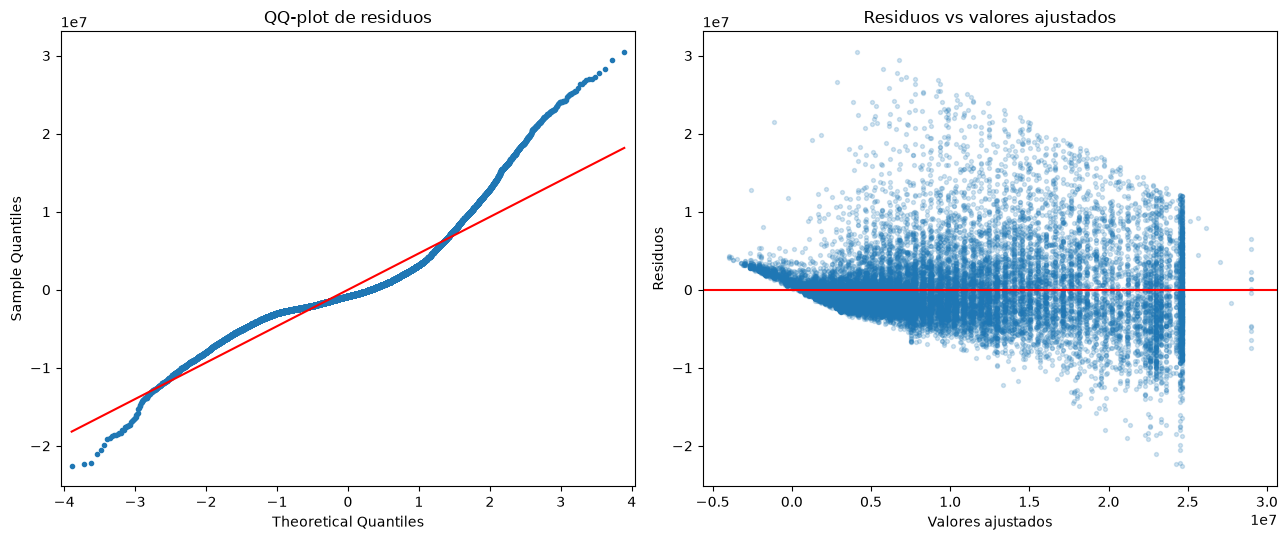

TEST DE NORMALIDAD (Shapiro-Wilk sobre los residuos)
  W = 0.8800 | p-valor = 3.309e-81
  Conclusión: se rechaza la normalidad (alfa = 0,05)

TEST DE HOMOCEDASTICIDAD (Breusch-Pagan)
  LM = 1255.30 | p-valor = 1.189e-242
  Conclusión: se rechaza la homocedasticidad (alfa = 0,05)


d:\Proyectos\Trabajo Fundamentos\TPE_CienciaDeDatos\Azucar\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 20331.
  res = hypotest_fun_out(*samples, **kwds)


In [39]:
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy import stats
import matplotlib.pyplot as plt

residuos = modelo.resid
ajustados = modelo.fittedvalues

# --- Gráficos ---
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))

sm.qqplot(residuos, line="s", ax=ax[0], markersize=3)
ax[0].set_title("QQ-plot de residuos")

ax[1].scatter(ajustados, residuos, alpha=0.2, s=8)
ax[1].axhline(0, color="r")
ax[1].set_xlabel("Valores ajustados")
ax[1].set_ylabel("Residuos")
ax[1].set_title("Residuos vs valores ajustados")

plt.tight_layout()
plt.show()

# --- Tests (salida por consola, debajo de los gráficos) ---
W, p_sw = stats.shapiro(residuos)
lm, p_bp, f_stat, p_f = het_breuschpagan(residuos, modelo.model.exog)

print("TEST DE NORMALIDAD (Shapiro-Wilk sobre los residuos)")
print(f"  W = {W:.4f} | p-valor = {p_sw:.3e}")
print(f"  Conclusión: {'se rechaza' if p_sw < 0.05 else 'no se rechaza'} la normalidad (alfa = 0,05)\n")

print("TEST DE HOMOCEDASTICIDAD (Breusch-Pagan)")
print(f"  LM = {lm:.2f} | p-valor = {p_bp:.3e}")
print(f"  Conclusión: {'se rechaza' if p_bp < 0.05 else 'no se rechaza'} la homocedasticidad (alfa = 0,05)")

**Diagnóstico de los supuestos**

- _Normalidad_: el QQ-plot muestra que los residuos se alejan de la línea en las colas, con asimetría positiva (1,41) y colas pesadas (curtosis 7,94). Shapiro-Wilk rechaza la normalidad (W = 0,88; p ≈ 3,3e-81). Con más de 5.000 filas el p-valor de Shapiro es aproximado, pero la magnitud del apartamiento hace que la conclusión no cambie.
- _Homocedasticidad_: el gráfico de residuos vs valores ajustados no tiene dispersión pareja, sino que se abre al crecer el valor ajustado. Breusch-Pagan rechaza la homocedasticidad (LM = 1255,30; p ≈ 1,2e-242).

Como se violan los dos supuestos, el test F del barrio y los p-valores del OLS no son confiables. Por eso la hipótesis se contrasta con **Kruskal-Wallis**, que compara rangos entre grupos y no exige normalidad ni varianzas iguales. Para respetar el "a igual ocupación y room_type", el test se aplica sobre los residuos de un modelo sin barrio (ingreso ~ ocupación + room_type), de modo que las diferencias que queden entre barrios no se deban a esas dos variables.

In [40]:
import statsmodels.formula.api as smf
from scipy import stats

# Modelo reducido: sin barrio
reducido = smf.ols(
    "estimated_revenue_l365d ~ estimated_occupancy_l365d + C(room_type)",
    data=df_multi).fit()
df_multi["residuos_reducido"] = reducido.resid

# Kruskal-Wallis: residuos agrupados por barrio
grupos = [g["residuos_reducido"].values
          for _, g in df_multi.groupby("neighbourhood_cleansed")]
H, p = stats.kruskal(*grupos)

k = len(grupos)
n = len(df_multi)
epsilon2 = (H - k + 1) / (n - k)   # tamaño del efecto

print("KRUSKAL-WALLIS (residuos del modelo sin barrio, agrupados por barrio)")
print(f"  Grupos (barrios) = {k} | n = {n}")
print(f"  H = {H:.2f} | gl = {k-1} | p-valor = {p:.3e}")
print(f"  Tamaño del efecto (epsilon²) = {epsilon2:.3f}")
print(f"  Conclusión: {'se rechaza' if p < 0.05 else 'no se rechaza'} H0 (alfa = 0,05)")

KRUSKAL-WALLIS (residuos del modelo sin barrio, agrupados por barrio)
  Grupos (barrios) = 30 | n = 20331
  H = 1053.64 | gl = 29 | p-valor = 3.936e-203
  Tamaño del efecto (epsilon²) = 0.050
  Conclusión: se rechaza H0 (alfa = 0,05)


**Resultado del contraste**

Kruskal-Wallis sobre los residuos agrupados por 30 barrios (n = 20.331): H = 1053,64; gl = 29; p ≈ 3,9e-203. Como p < 0,05, **se rechaza H0**: a igual ocupación y tipo de habitación, el ingreso anual estimado difiere entre barrios.

**Conclusión**

La evidencia respalda la hipótesis: el barrio influye en el ingreso anual estimado de un alojamiento, incluso descontando el efecto de la ocupación y del tipo de habitación. El tamaño del efecto es pequeño a moderado (epsilon² = 0,050), es decir que el barrio explica una parte acotada de la variación, y la mayor parte la explican la ocupación y el tipo de habitación. En el modelo OLS, los barrios con mayor ingreso respecto de Almagro son Puerto Madero, Palermo, Recoleta, Colegiales y Belgrano.
